# Claims Denial Tracker (synthetic data)
Run each cell from top to bottom. All data is synthetic - no real patient information.

## Step 1: Build the database

In [15]:
import sqlite3
import random
from datetime import date, timedelta

random.seed(42)

conn = sqlite3.connect("claims.db")
cur = conn.cursor()
cur.execute("DROP TABLE IF EXISTS claims")
cur.execute("""
CREATE TABLE claims (
    claim_id        INTEGER PRIMARY KEY,
    payer           TEXT,
    claim_type      TEXT,
    billed_amount   REAL,
    submitted_date  TEXT,
    status          TEXT,
    denial_reason   TEXT,
    touches         INTEGER,
    days_to_close   INTEGER
)
""")

payers = ["Payer A", "Payer B", "Payer C", "Payer D"]
claim_types = ["Office Visit", "Lab", "Imaging", "Surgery", "Pharmacy"]
reasons = ["Missing prior authorization", "Incorrect patient info",
           "Not medically necessary", "Duplicate claim", "Out of network",
           "Missing documentation"]
reason_weights = [30, 25, 12, 8, 10, 15]
denial_rate = {"Payer A": 0.10, "Payer B": 0.14, "Payer C": 0.28, "Payer D": 0.12}

rows = []
for i in range(1, 2001):
    payer = random.choice(payers)
    ctype = random.choice(claim_types)
    amount = round(random.uniform(80, 6000), 2)
    d = date(2025, 1, 1) + timedelta(days=random.randint(0, 364))
    if random.random() < denial_rate[payer]:
        reason = random.choices(reasons, reason_weights)[0]
        touches = random.randint(2, 6)
        days = random.randint(15, 75)
        status = random.choice(["Resolved", "Resolved", "Denied"])
    else:
        reason, touches, days, status = None, 1, random.randint(5, 25), "Paid"
    rows.append((i, payer, ctype, amount, d.isoformat(), status, reason, touches, days))

cur.executemany("INSERT INTO claims VALUES (?,?,?,?,?,?,?,?,?)", rows)
conn.commit()
print("Database built:", len(rows), "synthetic claims")

Database built: 2000 synthetic claims


## Step 2: SQL queries

In [16]:
def run(title, sql):
    print(f"\n=== {title} ===")
    for r in cur.execute(sql):
        print(r)

run("Q1: Overall denial rate",
    """SELECT COUNT(*) AS total_claims,
              SUM(denial_reason IS NOT NULL) AS denied,
              ROUND(100.0 * SUM(denial_reason IS NOT NULL) / COUNT(*), 1) AS denial_pct
       FROM claims""")

run("Q2: Which denial reasons are most common?",
    """SELECT denial_reason, COUNT(*) AS n
       FROM claims
       WHERE denial_reason IS NOT NULL
       GROUP BY denial_reason
       ORDER BY n DESC""")

run("Q3: Denial rate by payer",
    """SELECT payer,
              COUNT(*) AS claims,
              ROUND(100.0 * SUM(denial_reason IS NOT NULL) / COUNT(*), 1) AS denial_pct
       FROM claims
       GROUP BY payer
       ORDER BY denial_pct DESC""")

run("Q4: Average days to close by denial reason",
    """SELECT denial_reason,
              AVG(days_to_close) AS avg_days
       FROM claims
       WHERE denial_reason IS NOT NULL
       GROUP BY denial_reason
       ORDER BY avg_days DESC""")

run("Q5: Total days spent by denial reason",
    """SELECT denial_reason,
              COUNT(*) AS denied_claims,
              ROUND(AVG(days_to_close), 1) AS avg_days,
              SUM(days_to_close) AS total_days,
              SUM(touches) AS total_touches
       FROM claims
       WHERE denial_reason IS NOT NULL
       GROUP BY denial_reason
       ORDER BY total_touches DESC""")

run("Q6: Denial rate by claim type",
    """SELECT claim_type,
              COUNT(*) AS claims,
              ROUND(100.0 * SUM(denial_reason IS NOT NULL) / COUNT(*), 1) AS denial_pct
       FROM claims
       GROUP BY claim_type
       ORDER BY denial_pct DESC""")


conn.close()


=== Q1: Overall denial rate ===
(2000, 321, 16.1)

=== Q2: Which denial reasons are most common? ===
('Missing prior authorization', 111)
('Incorrect patient info', 79)
('Missing documentation', 46)
('Duplicate claim', 31)
('Not medically necessary', 29)
('Out of network', 25)

=== Q3: Denial rate by payer ===
('Payer C', 544, 28.9)
('Payer B', 460, 13.3)
('Payer D', 505, 12.3)
('Payer A', 491, 8.4)

=== Q4: Average days to close by denial reason ===
('Not medically necessary', 48.62068965517241)
('Incorrect patient info', 48.45569620253165)
('Duplicate claim', 47.16129032258065)
('Missing prior authorization', 47.090090090090094)
('Missing documentation', 44.82608695652174)
('Out of network', 41.08)

=== Q5: Total days spent by denial reason ===
('Missing prior authorization', 111, 47.1, 5227, 454)
('Incorrect patient info', 79, 48.5, 3828, 294)
('Missing documentation', 46, 44.8, 2062, 191)
('Duplicate claim', 31, 47.2, 1462, 130)
('Not medically necessary', 29, 48.6, 1410, 113)
('O

## Step 3: Chart the rework (Python + pandas)

                 denial_reason  total_touches  pct_of_rework
0  Missing prior authorization            454           35.7
1       Incorrect patient info            294           23.1
2        Missing documentation            191           15.0
3              Duplicate claim            130           10.2
4      Not medically necessary            113            8.9
5               Out of network             91            7.1


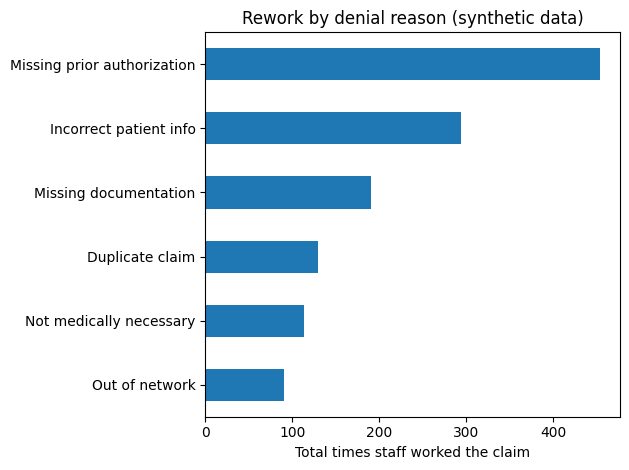

In [10]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("claims.db")

df = pd.read_sql("""
    SELECT denial_reason, SUM(touches) AS total_touches
    FROM claims
    WHERE denial_reason IS NOT NULL
    GROUP BY denial_reason
    ORDER BY total_touches DESC
""", conn)

df["pct_of_rework"] = (100 * df["total_touches"] / df["total_touches"].sum()).round(1)
print(df)

ax = df.plot.barh(x="denial_reason", y="total_touches", legend=False)
ax.invert_yaxis()
plt.title("Rework by denial reason (synthetic data)")
plt.xlabel("Total times staff worked the claim")
plt.ylabel("")
plt.tight_layout()
plt.show()

conn.close()